In [1]:
import time 

start_time = time.perf_counter()

#Environment Variables
run_name = "model_sample_1" # change per experiment, e.g. "model_unbalanced"
#Output file name for journal

In [2]:
#This script loads and verifies the test dataset for the GeoGuessr project
import pandas as pd
from pathlib import Path

image_dir = Path("/work/cssema416/202710/11/datasets/OpenWorld/extracted_train")
out_dir = Path("output")/run_name
out_dir.mkdir(parents=True, exist_ok=True)

#Verifies the shape
csv_path = "/work/cssema416/202710/11/datasets/OpenWorld/train.csv"
df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

#This confirms data loaded as expected
print("Metadata rows:", len(df))
print("Metadata columns:", len(df.columns))

#nunique is num of unique elements
print("Unique countries:", df["country"].nunique())

print("Country counts:")
print(df["country"].value_counts().head())

/tmp/ipykernel_2178162/3754144630.py:11: DtypeWarning: Columns (0: sub-region, 1: unique_sub-region) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


Dataset shape: (4894684, 32)
                 id   latitude   longitude  \
0  3859149887465501 -43.804769 -176.614093   
1   574181207305439 -43.796611 -176.660483   
2   333574322129026 -43.818092 -176.578383   
3   636305258168031 -44.052910 -176.633065   
4   166741299029322 -43.748077 -176.329626   

                                  thumb_original_url country  \
0  https://scontent-cdg4-1.xx.fbcdn.net/m1/v/t6/A...      NZ   
1  https://scontent-cdg4-1.xx.fbcdn.net/m1/v/t6/A...      NZ   
2  https://scontent-cdg4-1.xx.fbcdn.net/m1/v/t6/A...      NZ   
3  https://scontent-cdg4-1.xx.fbcdn.net/m1/v/t6/A...      NZ   
4  https://scontent-cdg4-1.xx.fbcdn.net/m1/v/t6/A...      NZ   

                 sequence    captured_at  lon_bin  lat_bin    cell  ...  \
0  1qOCfogkQ5uE4ZvEf_4n2A  1547559856000        0        8  (0, 8)  ...   
1  5rdtj6tui6qdlg8q812ul2  1567257056000        0        8  (0, 8)  ...   
2  nJcst1M2bFUxSOA54CZiy9  1531231715132        0        8  (0, 8)  ...   
3  BGSwcf

In [3]:
from pathlib import Path
import os

# Find images inside extracted_test and all its subfolders
image_lookup = {}
for root, _, files in os.walk(image_dir):
    for f in files:
        if f.lower().endswith(".jpg"):
            image_lookup[f[:-4]] = os.path.join(root, f)

# Match image IDs to the CSV
df["id"] = df["id"].astype(str).str.strip()
df["image_path"] = df["id"].map(image_lookup)

print("Unique image IDs:", len(image_lookup))
print("Unique CSV IDs:", df["id"].nunique())
print("Matching IDs:", df["image_path"].notna().sum())
print("CSV IDs missing images:", df["image_path"].isna().sum())


Unique image IDs: 4894684


Unique CSV IDs: 4894684
Matching IDs: 4894684
CSV IDs missing images: 0


In [4]:
baseline_country = "US" #this was the highest occuring country in dataset

data = df["country"]
y_pred = [baseline_country] * len(data)

accuracy = (data == y_pred).mean()

print("Baseline country:", baseline_country)
print("Baseline accuracy:", accuracy)
print("Number of images:", len(data))
print("Number of correct guesses:", len(data) * accuracy)
print("Number of countries:", data.nunique())

Baseline country: US
Baseline accuracy: 0.2489770534727063
Number of images: 4894684
Number of correct guesses: 1218664.0
Number of countries: 222


In [5]:
#This section is responsible for two things:
#Sets transformer (which compiles all images to the same input size for CNN)
#Initializes Resnet with it's own weights
import torch
import torchvision.models as models
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image


# Define the image transformation
transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

#This is where model is made(which can be changed)
weights = models.ResNet101_Weights.DEFAULT

model = models.resnet101(weights=weights)

# Replace the ImageNet classification layer
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, df["country"].nunique())

#print(model) #if you need to see model structure


In [6]:
#Encoder
# Country -> IDs for Unique Countries
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["country_label"] = label_encoder.fit_transform(df["unique_country"])

num_countries = len(label_encoder.classes_)

print("Number of countries:", num_countries)
print("Country classes:", label_encoder.classes_)

Number of countries: 222
Country classes: ['AD' 'AE' 'AF' 'AG' 'AI' 'AL' 'AM' 'AO' 'AR' 'AT' 'AU' 'AW' 'AX' 'AZ'
 'BA' 'BB' 'BD' 'BE' 'BF' 'BG' 'BH' 'BI' 'BJ' 'BM' 'BN' 'BO' 'BQ' 'BR'
 'BS' 'BT' 'BW' 'BY' 'BZ' 'CA' 'CD' 'CF' 'CG' 'CH' 'CI' 'CL' 'CM' 'CN'
 'CO' 'CR' 'CU' 'CV' 'CW' 'CX' 'CY' 'CZ' 'DE' 'DJ' 'DK' 'DM' 'DO' 'DZ'
 'EC' 'EE' 'EG' 'ER' 'ES' 'ET' 'FI' 'FJ' 'FK' 'FM' 'FO' 'FR' 'GA' 'GB'
 'GD' 'GE' 'GF' 'GG' 'GH' 'GI' 'GL' 'GM' 'GN' 'GP' 'GQ' 'GR' 'GT' 'GW'
 'GY' 'HK' 'HN' 'HR' 'HT' 'HU' 'ID' 'IE' 'IL' 'IM' 'IN' 'IQ' 'IR' 'IS'
 'IT' 'JE' 'JM' 'JO' 'JP' 'KE' 'KG' 'KH' 'KI' 'KM' 'KN' 'KP' 'KR' 'KW'
 'KZ' 'LA' 'LB' 'LC' 'LI' 'LK' 'LR' 'LS' 'LT' 'LU' 'LV' 'LY' 'MA' 'MC'
 'MD' 'ME' 'MF' 'MG' 'MK' 'ML' 'MM' 'MN' 'MO' 'MQ' 'MR' 'MS' 'MT' 'MU'
 'MV' 'MW' 'MX' 'MY' 'MZ' 'NC' 'NE' 'NG' 'NI' 'NL' 'NO' 'NP' 'NZ' 'OM'
 'PA' 'PE' 'PF' 'PG' 'PH' 'PK' 'PL' 'PR' 'PS' 'PT' 'PW' 'PY' 'QA' 'RE'
 'RO' 'RS' 'RU' 'RW' 'SA' 'SB' 'SD' 'SE' 'SG' 'SI' 'SJ' 'SK' 'SL' 'SM'
 'SN' 'SO' 'SR' 'SS' 'ST' 'SV' 'SX'

In [ ]:
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler, TensorDataset
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt
import os

#See how to setup online server with team
device = "cuda" if torch.cuda.is_available() else "cpu"
n_workers = len(os.sched_getaffinity(0))
 
#becareful of n, as too large will obviously error 
# (after 20ish seconds from what I've seen)
n_samples = 200_000   # images to sample from the full dataset (set to what you want)
K = 20                # keep only countries with at least K sampled images
sub = df.sample(n=min(n_samples, len(df)), random_state=0)

#This removes the smaller countries to train on more specific
sub_counts = sub["country_label"].value_counts()
sub = sub[sub["country_label"].isin(sub_counts[sub_counts >= K].index)]
assert len(sub) > 0, f"No countries have >= {K} images in a sample of {n_samples}; raise n_samples or lower K"

#sets training set and testing set (tr, te)
tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=0).split(sub, groups=sub["sequence"]))
train_df, test_df = sub.iloc[tr], sub.iloc[te]


#Dataset for handling the frame
class GeoDataset(Dataset):
    def __init__(self, frame):
        self.paths = frame["image_path"].tolist()
        self.labels = frame["country_label"].tolist()
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return transform(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

#This is where balancing occurs
#class_counts = train_df["country_label"].value_counts() #retrieves the counts of each country
# sample_weights = train_df["country_label"].map(lambda c: 1.0/class_counts[c]).tolist() #sets larger weights to more prominent countries
# sampler = WeightedRandomSampler(sample_weights, num_samples=len(train_df), replacement=True)

#This is a MLP for classification
class ResidualBlock(nn.Module):
    def __init__(self, features, dropout=0.3):
        super().__init__()

        self.block = nn.Sequential(
            nn.Linear(features, features),
            nn.BatchNorm1d(features),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(features, features),
            nn.BatchNorm1d(features)
        )

        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(x + self.block(x))


class Head(nn.Module):
    def __init__(self, n, in_features=2048):
        super().__init__()

        self.fc = nn.Sequential(
            # First feature reduction
            nn.Linear(in_features, 1024),
            nn.BatchNorm1d(1024),
            nn.GELU(),
            nn.Dropout(0.3),

            # Residual learning
            ResidualBlock(1024, dropout=0.3),

            # Second feature reduction
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(0.3),

            # Additional residual learning
            ResidualBlock(512, dropout=0.2),

            # Final classification
            nn.Linear(512, n)
        )

    def forward(self, x):
        return self.fc(x)


head = Head(num_countries, in_features=num_features).to(device)

#This sets the fc to the identity function to pass to the decoder
model.fc = nn.Identity()
model = model.to(device).eval()


def get_features(frame):
    #Loads images in batches to avoid loading all dataset into mem
    loader = DataLoader(GeoDataset(frame), batch_size=128, shuffle=False, num_workers=n_workers)
    feats = []
    labels = []
    with torch.no_grad():
        for x, y in loader:
            feats.append(model(x.to(device)).cpu())   # move to CPU each batch so GPU memory stays flat
            labels.append(y)
    return torch.cat(feats).cpu(), torch.cat(labels).cpu()

cache = Path("output") / f"feats_resnet_K{K}_n{n_samples}.pt"   # name must change if backbone, K, or n_samples change
if cache.exists():
    train_feats, train_y, test_feats, test_y = torch.load(cache)
else:
    train_feats, train_y = get_features(train_df)
    test_feats, test_y = get_features(test_df)
    torch.save((train_feats, train_y, test_feats, test_y), cache)


train_loader = DataLoader(TensorDataset(train_feats, train_y), batch_size=128, shuffle=True, drop_last=True)  # drop_last: BatchNorm fails on a batch of size 1
test_loader  = DataLoader(TensorDataset(test_feats, test_y),  batch_size=128, shuffle=False)
 
for p in model.parameters():
    p.requires_grad = False
for p in model.fc.parameters():
    p.requires_grad = True
model = model.to(device)

In [ ]:
#training function
import copy

def train_model(model, train_loader, test_loader,
                loss_fn, optimizer, epochs):

    train_losses, test_losses = [], []
    train_accs, test_accs = [], []

    best_acc = -1
    best_state = None

    for epoch in range(epochs):

        # Training
        model.train()

        total_loss = 0
        correct = 0
        total = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()

            out = model(x)
            loss = loss_fn(out, y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)

        train_losses.append(total_loss / len(train_loader))
        train_accs.append(correct / total)

        # Evaluation
        model.eval()

        total_loss = 0
        correct = 0
        total = 0

        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)

                out = model(x)
                loss = loss_fn(out, y)

                total_loss += loss.item()
                correct += (out.argmax(1) == y).sum().item()
                total += len(y)

        test_losses.append(total_loss / len(test_loader))
        test_accs.append(correct / total)

        # Save best checkpoint
        if test_accs[-1] > best_acc:
            best_acc = test_accs[-1]
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch+1}: "
            f"Train acc {train_accs[-1]:.3f}, "
            f"Test acc {test_accs[-1]:.3f}"
        )

    model.load_state_dict(best_state)

    return (
        train_losses,
        test_losses,
        train_accs,
        test_accs,
        best_state
    )


In [9]:
#calling train method
learning_rate = 0.001
optimizer = torch.optim.AdamW(head.parameters(), lr=learning_rate, weight_decay=0.0001)
loss_fn = nn.CrossEntropyLoss()
num_epochs = 5

train_losses, test_losses, train_accs, test_accs, best_state = train_model(head, train_loader, test_loader, loss_fn, optimizer, epochs=num_epochs)

#this saves the model (which we will use for demo and more test code)
torch.save(best_state, out_dir/f"train_{run_name}.pt")

Epoch 1: Train acc 0.424, Test acc 0.483


Epoch 2: Train acc 0.492, Test acc 0.519


Epoch 3: Train acc 0.529, Test acc 0.534


Epoch 4: Train acc 0.558, Test acc 0.552


Epoch 5: Train acc 0.583, Test acc 0.559


Epoch 6: Train acc 0.606, Test acc 0.564


... (5 outputs left out)

Epoch 12: Train acc 0.709, Test acc 0.574


Epoch 13: Train acc 0.722, Test acc 0.575


Epoch 14: Train acc 0.733, Test acc 0.573


Epoch 15: Train acc 0.744, Test acc 0.574


In [ ]:
#everything below is testing and analyzing accuracy
from sklearn.metrics import balanced_accuracy_score

def eval_model(model, loader):
    model.eval()
    y_true = []
    y_pred = []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(device))
            y_pred += out.argmax(1).cpu().tolist()
            y_true += y.tolist()
    return y_true, y_pred

In [11]:
from sklearn.metrics import balanced_accuracy_score

y_true, y_pred = eval_model(head, test_loader)

majority = train_df["country_label"].mode()[0]
baseline_acc = (test_df["country_label"] == majority).mean()

print("Accuracy:", sum(t == p for t, p in zip(y_true, y_pred))/len(y_true))
print("Baseline accuracy:", baseline_acc)
print("Balanced accuracy:", balanced_accuracy_score(y_true, y_pred))

Accuracy: 0.5749033928191789
Baseline accuracy: 0.24667658792191388
Balanced accuracy: 0.2961388483914377


In [ ]:
import json
import numpy as np

results = {
    "train_losses": train_losses, "test_losses": test_losses,
    "train_accs": train_accs,     "test_accs": test_accs,
    "baseline_acc": float(baseline_acc),
    "accuracy": sum(t == p for t, p in zip(y_true, y_pred))/len(y_true),
    "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
}
with open(out_dir/"history.json", "w") as f:
    json.dump(results, f)

np.savez(out_dir/"preds.npz", y_true=np.array(y_true), y_pred=np.array(y_pred), classes=label_encoder.classes_.astype(str))

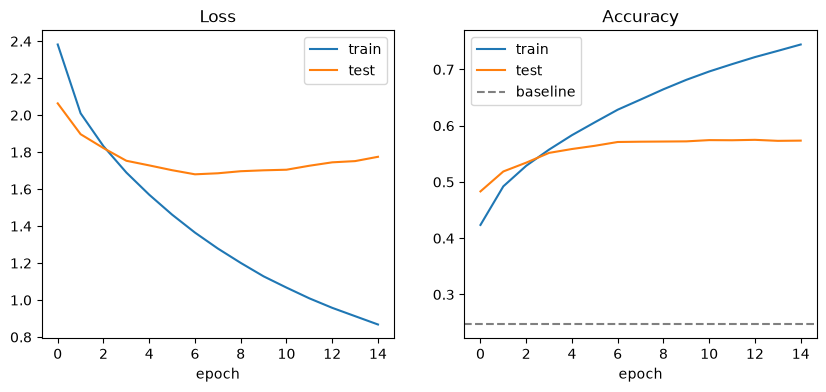

In [13]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="train")
plt.plot(test_losses, label="test")
plt.title("Loss")
plt.xlabel("epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label="train")
plt.plot(test_accs, label="test")
plt.axhline(baseline_acc, color="gray", linestyle="--", label="baseline")
plt.title("Accuracy")
plt.xlabel("epoch")
plt.legend()

plt.savefig(out_dir/"curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
end_time = time.perf_counter()
execution_time = end_time - start_time
print(execution_time)

940.1864668158814
